# Experiment 03: Multiclass Classification using SVM
**Aim:** Implement Support Vector Machine (SVM) algorithm for multiclass handwritten digit classification (0-9).

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load dataset & Normalize
digits = load_digits()
X_norm = digits.data / 16.0
X_tr, X_te, y_tr, y_te = train_test_split(X_norm, digits.target, test_size=0.2, random_state=42, stratify=digits.target)
print(f"Training samples: {X_tr.shape[0]}, Testing samples: {X_te.shape[0]}")

Training samples: 1437, Testing samples: 360


In [3]:
# 2. Train SVM & Evaluate
svm_clf = SVC(kernel='rbf', C=10.0, gamma=0.1, random_state=42)
svm_clf.fit(X_tr, y_tr)
y_pred = svm_clf.predict(X_te)

print(f"Accuracy: {accuracy_score(y_te, y_pred) * 100:.2f}%\n")
print("=== Classification Report ===")
print(classification_report(y_te, y_pred, digits=4))

Accuracy: 99.44%

=== Classification Report ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9730    1.0000    0.9863        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     0.9730    1.0000    0.9863        36
           8     1.0000    0.9714    0.9855        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9944       360
   macro avg     0.9946    0.9944    0.9944       360
weighted avg     0.9946    0.9944    0.9944       360



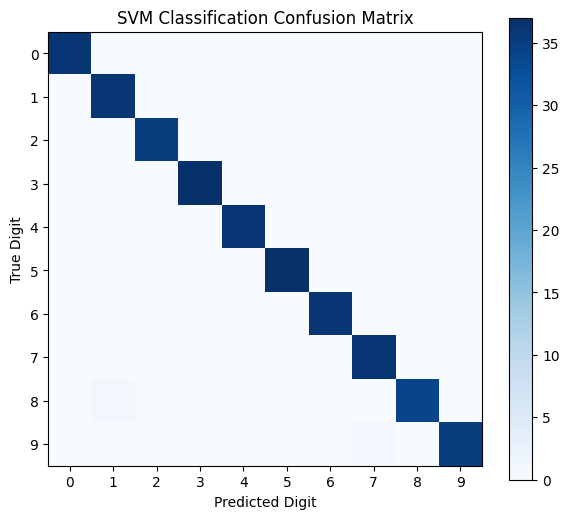

In [4]:
# 3. Confusion Matrix Plot
cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues')
plt.title('SVM Classification Confusion Matrix')
plt.colorbar()
plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel('Predicted Digit')
plt.ylabel('True Digit')
plt.show()